THEORETICAL ROULETTE RESULTS
-----------------------------------
P(win) = 0.4864864864864865
P(loss) = 0.5135135135135135
E[X_R] = -0.027027027027026973
Var(X_R) = 0.9992695398100804

MONTE CARLO UNIT-BET RESULTS
-----------------------------------
Simulated E[X_R] = -0.028258
Theoretical E[X_R] = -0.027027027027026973
Difference = -0.0012309729729730254
Standard error = 0.0009996347031841584
Difference in standard errors = -1.2314228078036709

Simulated Var(X_R) = 0.9992014854360004
Theoretical Var(X_R) = 0.9992695398100804

PASS: Unit-bet simulation agrees with theoretical expectation.

BANKROLL ALLOCATION RESULTS
-----------------------------------

  Bet  Theoretical_Expected_Profit  Simulated_Mean_Profit  Theoretical_Variance  Simulated_Variance
  0.0                    -0.000000                0.00000              0.000000            0.000000
 25.0                    -0.675676               -0.70645            624.543462          624.500928
 50.0                    -1.351351     

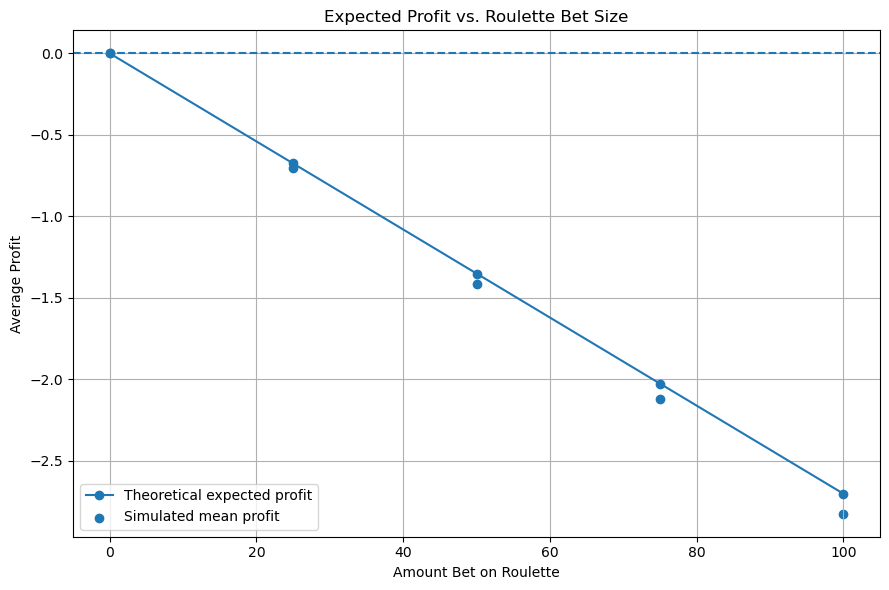

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# PART I: EUROPEAN ROULETTE
# Verify expectation, variance, and bankroll decision
# ============================================================

rng = np.random.default_rng(42)

num_trials = 1_000_000

B = 100.0


# European roulette red numbers
red_numbers = np.array([
    1, 3, 5, 7, 9,
    12, 14, 16, 18,
    19, 21, 23, 25, 27,
    30, 32, 34, 36
])


# ============================================================
# Theoretical unit-bet results
# ============================================================

p_win = 18 / 37
p_loss = 19 / 37

theoretical_mean = (
    p_win - p_loss
)

theoretical_variance = (
    1 - theoretical_mean**2
)


print("THEORETICAL ROULETTE RESULTS")
print("-----------------------------------")

print(
    "P(win) =",
    p_win
)

print(
    "P(loss) =",
    p_loss
)

print(
    "E[X_R] =",
    theoretical_mean
)

print(
    "Var(X_R) =",
    theoretical_variance
)


# ============================================================
# Simulate roulette outcomes
# ============================================================

spins = rng.integers(
    0,
    37,
    size=num_trials
)


# Determine whether each spin is red
wins = np.isin(
    spins,
    red_numbers
)


# Unit payoff:
# +1 if red
# -1 otherwise
X_R = np.where(
    wins,
    1.0,
    -1.0
)


# ============================================================
# Verify expectation and variance
# ============================================================

simulated_mean = np.mean(
    X_R
)

simulated_variance = np.var(
    X_R
)


standard_error_mean = np.sqrt(
    theoretical_variance
    /
    num_trials
)


mean_difference = (
    simulated_mean
    -
    theoretical_mean
)


z_score = (
    mean_difference
    /
    standard_error_mean
)


print()
print("MONTE CARLO UNIT-BET RESULTS")
print("-----------------------------------")

print(
    "Simulated E[X_R] =",
    simulated_mean
)

print(
    "Theoretical E[X_R] =",
    theoretical_mean
)

print(
    "Difference =",
    mean_difference
)

print(
    "Standard error =",
    standard_error_mean
)

print(
    "Difference in standard errors =",
    z_score
)

print()

print(
    "Simulated Var(X_R) =",
    simulated_variance
)

print(
    "Theoretical Var(X_R) =",
    theoretical_variance
)


if abs(z_score) < 4:

    print()
    print(
        "PASS: Unit-bet simulation agrees "
        "with theoretical expectation."
    )

else:

    print()
    print(
        "WARNING: Unit-bet simulation differs "
        "from theory more than expected."
    )


# ============================================================
# Test different bankroll allocations
# ============================================================

bet_amounts = np.array([
    0.00,
    0.25 * B,
    0.50 * B,
    0.75 * B,
    1.00 * B
])


results = []


for b_R in bet_amounts:

    # Profit for each simulated casino visit
    profit = (
        b_R * X_R
    )

    # Simulated average profit
    simulated_profit = np.mean(
        profit
    )

    # Theoretical expected profit
    theoretical_profit = (
        b_R
        *
        theoretical_mean
    )

    # Theoretical variance
    theoretical_profit_variance = (
        b_R**2
        *
        theoretical_variance
    )

    # Simulated variance
    simulated_profit_variance = np.var(
        profit
    )

    results.append({
        "Bet": b_R,
        "Theoretical_Expected_Profit":
            theoretical_profit,
        "Simulated_Mean_Profit":
            simulated_profit,
        "Theoretical_Variance":
            theoretical_profit_variance,
        "Simulated_Variance":
            simulated_profit_variance
    })


results_df = pd.DataFrame(
    results
)


print()
print("BANKROLL ALLOCATION RESULTS")
print("-----------------------------------")
print()

print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# Find best theoretical strategy
# ============================================================

best_index = np.argmax(
    results_df[
        "Theoretical_Expected_Profit"
    ]
)

best_bet = results_df.loc[
    best_index,
    "Bet"
]

best_expected_profit = results_df.loc[
    best_index,
    "Theoretical_Expected_Profit"
]


print()
print("OPTIMAL STRATEGY")
print("-----------------------------------")

print(
    "Best roulette bet =",
    best_bet
)

print(
    "Maximum theoretical expected profit =",
    best_expected_profit
)


# ============================================================
# Verify that no-bet strategy is best
# ============================================================

if best_bet == 0:

    print()
    print(
        "PASS: The optimal expected-value strategy "
        "is to bet nothing on roulette."
    )

else:

    print()
    print(
        "WARNING: Simulation/theory did not identify "
        "the expected optimal strategy."
    )


# ============================================================
# Plot expected profit versus amount bet
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(
    results_df["Bet"],
    results_df[
        "Theoretical_Expected_Profit"
    ],
    marker="o",
    label="Theoretical expected profit"
)


plt.scatter(
    results_df["Bet"],
    results_df[
        "Simulated_Mean_Profit"
    ],
    label="Simulated mean profit"
)


plt.axhline(
    0,
    linestyle="--"
)


plt.xlabel(
    "Amount Bet on Roulette"
)

plt.ylabel(
    "Average Profit"
)

plt.title(
    "Expected Profit vs. Roulette Bet Size"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(
    "roulette_bet_strategy_verification.png",
    dpi=300
)

plt.show()